# Task 2: Knowledge distillation
Teacher (MLP) vs hard-label student vs distilled student, loss `alpha*CE + (1-alpha)*T^2*KL(teacher||student)`. Sweep T and alpha; select on **dev**; report test, size, latency.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd()
while not (ROOT / "configs").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.utils import load_config
from src.data import load_base, make_split
from src.features import attach_views

DATA_SOURCE = "local"   # "local" (data/raw TSVs), "hf", or "synthetic" (smoke test only)
cfg = load_config(overrides={"data.source": DATA_SOURCE})
base = attach_views(load_base(cfg), cfg)
cfg["_n_classes"] = base.n_classes
print(base.label_names, {k: len(v) for k, v in base.texts.items()})

['business', 'health', 'politics', 'sports'] {'train': 1311, 'dev': 188, 'test': 376}


In [2]:
from task2_distillation.distill import run_distillation, select_best
cfg['task2']['seeds'] = [0, 1, 2]
df = run_distillation(base, cfg, cfg['task2']['seeds'])
best = select_best(df); print('best on dev:', best)

  [seed 0] teacher test F1=0.9027 params=2561284
  [seed 0] hard-label student test F1=0.9008 params=8004
  [seed 1] teacher test F1=0.9119 params=2561284
  [seed 1] hard-label student test F1=0.9008 params=8004
  [seed 2] teacher test F1=0.9142 params=2561284
  [seed 2] hard-label student test F1=0.9008 params=8004
best on dev: {'T': 4.0, 'alpha': 0.5, 'mean_dev_macro_f1': 0.8954274206344452}


In [3]:
d = df[df.model == 'student_distilled'].groupby(['T', 'alpha'])[['dev_macro_f1', 'test_macro_f1']].mean().round(4); d

dev_macro_f1  test_macro_f1
T   alpha                             
1.0 0.3          0.8950         0.8998
    0.5          0.8950         0.9006
    0.7          0.8950         0.9007
2.0 0.3          0.8950         0.9006
    0.5          0.8950         0.9026
    0.7          0.8950         0.9026
4.0 0.3          0.8939         0.8997
    0.5          0.8954         0.9016
    0.7          0.8950         0.9026

In [4]:
chosen = df[(df.model == 'student_distilled') & (df['T'] == best['T']) & (df.alpha == best['alpha'])].assign(model='student_distilled(best_on_dev)')
comp = pd.concat([df[df.model.isin(['teacher', 'student_hard', 'baseline_charLR'])], chosen])
table = comp.groupby('model')[['test_macro_f1', 'test_ece', 'params', 'size_kb', 'latency_ms']].agg(['mean', 'std']).round(4); table

test_macro_f1         test_ece          \
                                        mean     std     mean     std   
model                                                                   
baseline_charLR                       0.9250  0.0000   0.0664  0.0000   
student_distilled(best_on_dev)        0.9016  0.0042   0.0390  0.0087   
student_hard                          0.9008  0.0000   0.0651  0.0037   
teacher                               0.9096  0.0061   0.0374  0.0099   

                                   params          size_kb      latency_ms  \
                                     mean  std        mean  std       mean   
model                                                                        
baseline_charLR                  200004.0  0.0    781.2656  0.0        NaN   
student_distilled(best_on_dev)     8004.0  0.0     33.0361  0.0     0.0194   
student_hard                       8004.0  0.0     33.0361  0.0     0.0135   
teacher                         2561284.0  0.0  10007.2158  0.0     0.0581   

                                        
                                   std  
model                                   
baseline_charLR                    NaN  
student_distilled(best_on_dev)  0.0013  
student_hard                    0.0012  
teacher                         0.0010

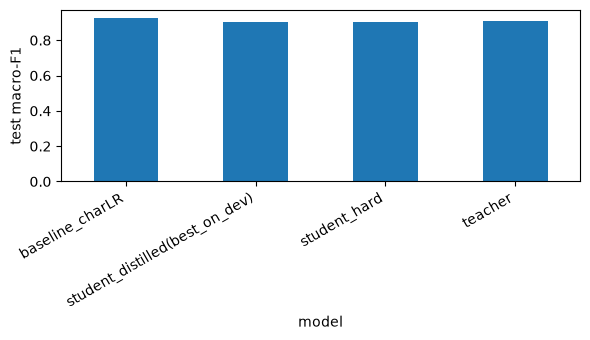

In [5]:
m = comp.groupby('model')['test_macro_f1'].mean()
plt.figure(figsize=(6, 3.5)); m.plot(kind='bar'); plt.ylabel('test macro-F1'); plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.show()

Full run that also writes `results/task2/`: `python -m task2_distillation.run`.